# Notebook 02 — Provisional Dreaddit Stress Classifier

**J26-IT-388 / Component 4 / PP1 — 2026**  
**Purpose:** train a reproducible _provisional_ text-only prediction pipeline for later SHAP/LIME explanation. **Not a clinical mental-health risk model.**

**Inputs:** `data/raw/dreaddit/dreaddit-train.csv`, `dreaddit-test.csv`.  
**Outputs:** `experiments/metrics/notebook02/`, `experiments/figures/notebook02/`, `models/dreaddit_tfidf_logreg.joblib` (model stays local).

**Experimental protection:** original test set is used _once_ for the final selected baseline evaluation; no feature fitting or model selection on the test set. Follow-up subgroup/contamination checks are descriptive, not used to tune the model.


## 0. Environment & run instructions

From repository root, activate `.venv` and install:

```cmd
python -m pip install pandas numpy scipy scikit-learn matplotlib seaborn joblib jupyter ipykernel
```

Open this notebook in VS Code, select your `.venv` kernel, then **Run All**. Paths work whether the notebook is launched from the repository root or `notebooks/` directory.


In [1]:
from pathlib import Path
import json, hashlib, platform, sys, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import sklearn, scipy, joblib, matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    classification_report, balanced_accuracy_score, brier_score_loss)

SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'raw' / 'dreaddit').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'raw' / 'dreaddit').exists(), 'Run from repository root or notebooks/ folder'
RAW = ROOT / 'data' / 'raw' / 'dreaddit'
MET = ROOT / 'experiments' / 'metrics' / 'notebook02'
FIG = ROOT / 'experiments' / 'figures' / 'notebook02'
MODEL = ROOT / 'models'
for d in (MET, FIG, MODEL): d.mkdir(parents=True,exist_ok=True)
print('Repository:', ROOT)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)


Repository: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388
Python: 3.12.0 | scikit-learn: 1.9.1


## 1. Load original splits and enforce schema

Only `text` is used for prediction; `label` is the target. Metadata (including subreddit, timestamp, label confidence, post ID, and lexical statistics) is **not** passed into the predictor. Keeping only raw text avoids target-derived or unverifiable metadata leakage.


In [2]:
train = pd.read_csv(RAW/'dreaddit-train.csv')
test = pd.read_csv(RAW/'dreaddit-test.csv')
required = {'text','label','post_id','subreddit'}
assert required.issubset(train.columns) and required.issubset(test.columns)
assert set(train.columns)==set(test.columns), 'Train/test columns differ'
assert train['label'].isin([0,1]).all() and test['label'].isin([0,1]).all()
assert train['text'].notna().all() and test['text'].notna().all()
assert train['text'].astype(str).str.strip().ne('').all() and test['text'].astype(str).str.strip().ne('').all()
X_train=train['text'].astype(str).reset_index(drop=True)
y_train=train['label'].astype(int).reset_index(drop=True)
X_test=test['text'].astype(str).reset_index(drop=True)
y_test=test['label'].astype(int).reset_index(drop=True)
groups=train['post_id'].astype(str).reset_index(drop=True)
print('Train/test:',train.shape,test.shape)
print('Train labels:',y_train.value_counts().sort_index().to_dict())
print('Test labels:',y_test.value_counts().sort_index().to_dict())
assert set(train['post_id'].astype(str)).isdisjoint(set(test['post_id'].astype(str))), 'Cross-split post ID overlap'


Train/test: (2838, 116) (715, 116)
Train labels: {0: 1350, 1: 1488}
Test labels: {0: 346, 1: 369}


## 2. Text overlap and groups — preregistered audit

Normalize only for overlap detection; the classifier uses the original text. `post_id` grouping is used **within training cross-validation** to prevent the same post appearing in both fold partitions. There may be multiple sentence-level labels within one post; do not discard these indiscriminately.


In [3]:
def norm_text(s):
    return ' '.join(str(s).casefold().split())
train_norm=X_train.map(norm_text)
test_norm=X_test.map(norm_text)
overlap_values=set(train_norm).intersection(set(test_norm))
overlap_mask=test_norm.isin(overlap_values)
train_dupes=int(train_norm.duplicated().sum())
print('Repeated training texts:',train_dupes)
print('Unique texts shared across splits:',len(overlap_values))
print('Held-out rows affected by exact normalized overlap:',int(overlap_mask.sum()))
print('Train unique post IDs:',groups.nunique(),'of',len(groups),'rows')
assert train['post_id'].astype(str).nunique() > 5
pd.DataFrame({'test_row':np.where(overlap_mask)[0]}).to_csv(MET/'overlap_test_row_indices.csv',index=False)


Repeated training texts: 18
Unique texts shared across splits: 3
Held-out rows affected by exact normalized overlap: 3
Train unique post IDs: 2343 of 2838 rows


## 3. Models — fixed before inspecting test performance

**Dummy:** always predicts the most frequent training class.  
**Logistic Regression:** word TF-IDF (1–2 grams, min_df=2, max_df=0.95, 20k features) + linear classifier (`C=1.0`, fixed random seed). The entire vectorizer sits inside the Pipeline, so each CV fold fits vocabulary and IDF on its training partition only.

No hyperparameter tuning is performed in this notebook.


In [4]:
dummy = Pipeline([
    ('tfidf',TfidfVectorizer(lowercase=True,ngram_range=(1,2),min_df=2,max_df=0.95,max_features=20000,strip_accents='unicode')),
    ('model',DummyClassifier(strategy='most_frequent'))
])
logreg = Pipeline([
    ('tfidf',TfidfVectorizer(lowercase=True,ngram_range=(1,2),min_df=2,max_df=0.95,max_features=20000,strip_accents='unicode')),
    ('model',LogisticRegression(C=1.0,max_iter=2000,solver='liblinear',random_state=SEED))
])
models={'dummy_most_frequent':dummy, 'tfidf_logistic_regression':logreg}


## 4. Training-only grouped stratified cross-validation

Five folds, groups=`post_id`, approximate class stratification. Grouping is **training-only**; the original published test set stays untouched. Group sizes vary, so class proportions can differ slightly between validation folds.


In [5]:
cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
folds=list(cv.split(X_train,y_train,groups))
fold_manifest=[]
for i,(tr,va) in enumerate(folds,1):
    assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[va]))
    fold_manifest.append({'fold':i,'train_n':len(tr),'validation_n':len(va),
                          'validation_positive_rate':round(float(y_train.iloc[va].mean()),4),
                          'overlapping_post_ids':0})
display(pd.DataFrame(fold_manifest))
pd.DataFrame(fold_manifest).to_csv(MET/'cv_folds_summary.csv',index=False)
scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','macro_f1':'f1_macro',
         'balanced_accuracy':'balanced_accuracy','roc_auc':'roc_auc'}
cv_rows=[]
for name,pipe in models.items():
    print('Running 5-fold training-only grouped CV:',name)
    out=cross_validate(pipe,X_train,y_train,cv=folds,scoring=scoring,n_jobs=1,error_score='raise')
    for i in range(5):
        cv_rows.append({'model':name,'fold':i+1,**{k:float(out['test_'+k][i]) for k in scoring}})
cv_df=pd.DataFrame(cv_rows)
cv_df.to_csv(MET/'cv_fold_metrics.csv',index=False)
cv_summary=cv_df.groupby('model')[list(scoring)].agg(['mean','std']).round(4)
display(cv_summary)
cv_summary.to_csv(MET/'cv_summary.csv')


,fold,train_n,validation_n,validation_positive_rate,overlapping_post_ids
0,1,2271,567,0.5238,0
1,2,2269,569,0.5255,0
2,3,2271,567,0.5238,0
3,4,2271,567,0.5238,0
4,5,2270,568,0.5246,0


Running 5-fold training-only grouped CV: dummy_most_frequent
Running 5-fold training-only grouped CV: tfidf_logistic_regression


accuracy         precision          recall          \
                              mean     std      mean     std    mean     std   
model                                                                          
dummy_most_frequent         0.5243  0.0007    0.5243  0.0007  1.0000  0.0000   
tfidf_logistic_regression   0.7579  0.0187    0.7422  0.0152  0.8252  0.0385   

                               f1         macro_f1         balanced_accuracy  \
                             mean     std     mean     std              mean   
model                                                                          
dummy_most_frequent        0.6879  0.0006    0.344  0.0003            0.5000   
tfidf_logistic_regression  0.7811  0.0200    0.755  0.0182            0.7545   

                                  roc_auc          
                              std    mean     std  
model                                              
dummy_most_frequent        0.0000   0.500  0.0000  
tfidf_logistic_regression  0.0182   0.843  0.0268

## 5. Fit both frozen baselines on all original training rows

We compare a predetermined Logistic Regression pipeline with a trivial Dummy baseline, without selecting hyperparameters using test outcomes.


In [6]:
for name,pipe in models.items():
    pipe.fit(X_train,y_train)
    print(name,'trained; vocabulary:',len(pipe.named_steps['tfidf'].vocabulary_))


dummy_most_frequent trained; vocabulary: 20000
tfidf_logistic_regression trained; vocabulary: 20000


## 6. One final held-out evaluation (original test split)

Metrics are descriptive of this benchmark task. A `0.5` fixed probability threshold is used; no threshold search is performed on test labels. These are **stress-related text predictions**, not mental-health diagnoses.


In [7]:
def evaluate(y,p,threshold=0.5):
    p=np.asarray(p,float)
    pred=(p>=threshold).astype(int)
    result={'n':len(y),'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),
            'macro_f1':f1_score(y,pred,average='macro',zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,pred),
            'roc_auc':roc_auc_score(y,p) if len(np.unique(y))==2 else None,
            'brier_score':brier_score_loss(y,p)}
    return result,pred

pred_tables=[]; scores=[]; saved_preds={}
for name,pipe in models.items():
    p=pipe.predict_proba(X_test)[:,list(pipe.named_steps['model'].classes_).index(1)]
    result,pred=evaluate(y_test,p)
    scores.append({'model':name,**result})
    saved_preds[name]=(p,pred)
    pred_tables.append(pd.DataFrame({'original_test_row':np.arange(len(y_test)),
        'model':name,'y_true':y_test.to_numpy(),'p_stress_related':p,'y_pred':pred,
        'subreddit':test['subreddit'].astype(str).to_numpy(),'cross_split_text_overlap':overlap_mask.to_numpy()}))
results=pd.DataFrame(scores)
display(results.round(4))
results.to_csv(MET/'heldout_test_metrics.csv',index=False)
pred_df=pd.concat(pred_tables,ignore_index=True)
pred_df.to_csv(MET/'heldout_test_predictions.csv',index=False)


,model,n,accuracy,precision,recall,f1,macro_f1,balanced_accuracy,roc_auc,brier_score
0,dummy_most_frequent,715,0.5161,0.5161,1.0000,0.6808,0.3404,0.5000,0.5000,0.4839
1,tfidf_logistic_regression,715,0.7161,0.6986,0.7913,0.7421,0.7132,0.7136,0.8162,0.1830


## 7. Save visual PP1 evaluation evidence


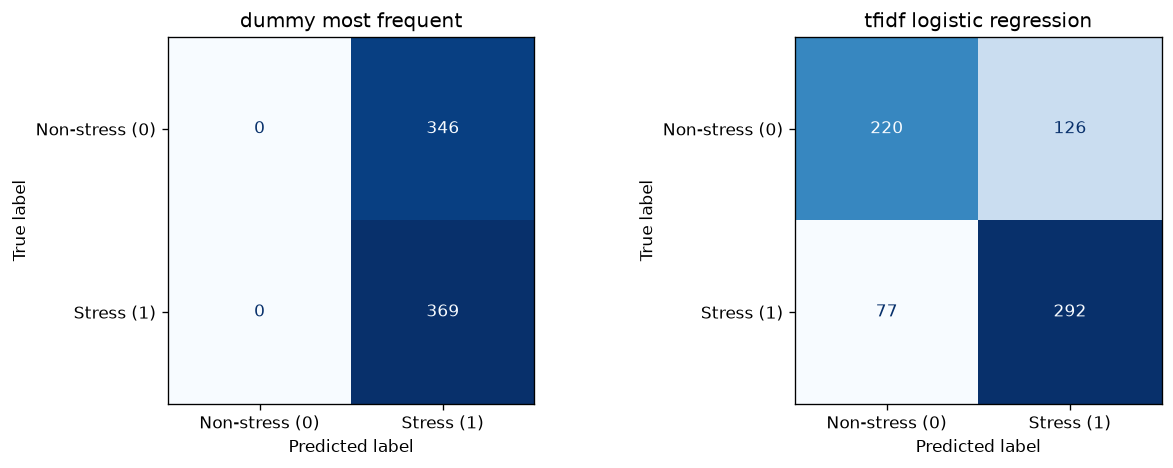

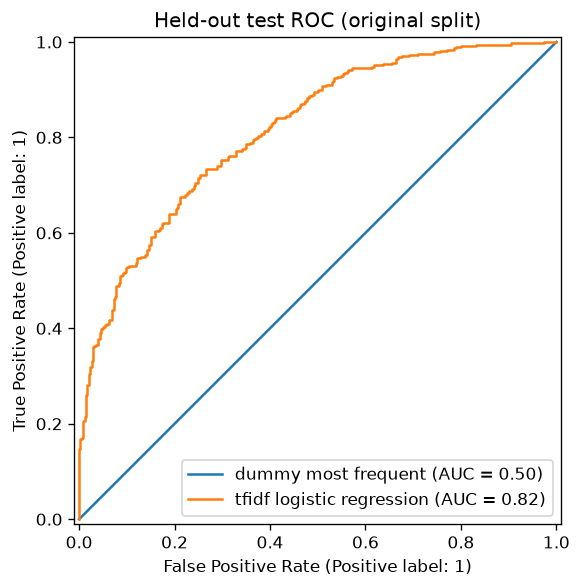

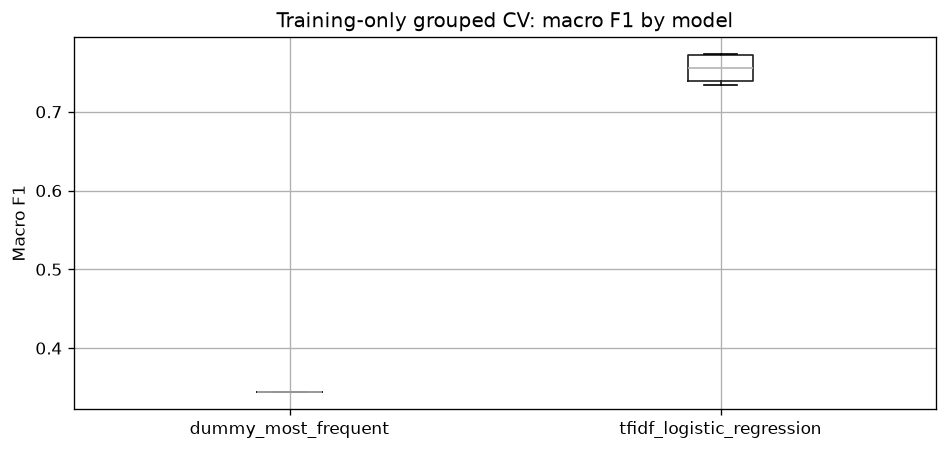

In [8]:
plt.rcParams.update({'figure.dpi':120})
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,(name,(p,pred)) in zip(axes,saved_preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred,labels=[0,1]),
        display_labels=['Non-stress (0)','Stress (1)']).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(name.replace('_',' '))
fig.tight_layout();fig.savefig(FIG/'01_confusion_matrices.png',bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(6,5))
for name,(p,pred) in saved_preds.items():
    RocCurveDisplay.from_predictions(y_test,p,ax=ax,name=name.replace('_',' '))
ax.set_title('Held-out test ROC (original split)')
fig.tight_layout();fig.savefig(FIG/'02_roc_curves.png',bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(8,4))
cv_df.boxplot(column='macro_f1',by='model',ax=ax)
ax.set_title('Training-only grouped CV: macro F1 by model')
ax.set_xlabel('');ax.set_ylabel('Macro F1')
fig.suptitle('');fig.tight_layout();fig.savefig(FIG/'03_grouped_cv_macro_f1.png',bbox_inches='tight');plt.show()


## 8. Contamination-sensitive held-out evaluation

Exclude ONLY original test rows whose normalized text appears anywhere in original training. This is a sensitivity analysis, **not** the primary original-split result. The trained model is unchanged and no test samples are used for fitting.


In [9]:
rows=[]
clean_mask=(~overlap_mask).to_numpy()
for name,(p,pred) in saved_preds.items():
    result,_=evaluate(y_test.to_numpy()[clean_mask],p[clean_mask])
    rows.append({'model':name,'subset':'overlap_excluded','excluded_rows':int(overlap_mask.sum()),**result})
sensitivity=pd.DataFrame(rows)
display(sensitivity.round(4))
sensitivity.to_csv(MET/'overlap_excluded_test_metrics.csv',index=False)


,model,subset,excluded_rows,n,accuracy,precision,recall,f1,macro_f1,balanced_accuracy,roc_auc,brier_score
0,dummy_most_frequent,overlap_excluded,3,712,0.5154,0.5154,1.0000,0.6803,0.3401,0.5000,0.500,0.4846
1,tfidf_logistic_regression,overlap_excluded,3,712,0.7177,0.6986,0.7956,0.7439,0.7147,0.7152,0.818,0.1825


## 9. Training duplicate sensitivity (retrained model, compare only on original test)

As an **additional robustness experiment**, remove repeated normalized training texts, keeping the first occurrence. Some repeated texts have disagreeing labels; this experiment measures sensitivity rather than proving which label is correct. It is not used to select/tune the final saved model.


In [10]:
keep=(~train_norm.duplicated()).to_numpy()
dedup_pipe=Pipeline([
    ('tfidf',TfidfVectorizer(lowercase=True,ngram_range=(1,2),min_df=2,max_df=0.95,max_features=20000,strip_accents='unicode')),
    ('model',LogisticRegression(C=1.0,max_iter=2000,solver='liblinear',random_state=SEED))])
dedup_pipe.fit(X_train[keep],y_train[keep])
dedup_p=dedup_pipe.predict_proba(X_test)[:,1]
dedup_result,_=evaluate(y_test,dedup_p)
dedup_out={'training_rows_original':int(len(X_train)),'training_rows_after_dedup':int(keep.sum()),
           'removed':int((~keep).sum()),'dedup_model_test_metrics':dedup_result}
print(json.dumps(dedup_out,indent=2))
(MET/'train_duplicate_sensitivity.json').write_text(json.dumps(dedup_out,indent=2),encoding='utf-8')


{
  "training_rows_original": 2838,
  "training_rows_after_dedup": 2820,
  "removed": 18,
  "dedup_model_test_metrics": {
    "n": 715,
    "accuracy": 0.7202797202797203,
    "precision": 0.7007125890736342,
    "recall": 0.7994579945799458,
    "f1": 0.7468354430379747,
    "macro_f1": 0.7171677215189873,
    "balanced_accuracy": 0.7176480724344816,
    "roc_auc": 0.8167285430079735,
    "brier_score": 0.1828462560436234
  }
}


432

## 10. Subreddit subgroup audit

Descriptive metrics for the frozen Logistic Regression model. Interpret cautiously for small subgroups and because subreddit is correlated with labeling context. **Do not select model features or thresholds based on these results.**


,subreddit,positive_rate,n,accuracy,precision,recall,f1,macro_f1,balanced_accuracy,roc_auc,brier_score
0,anxiety,0.578,147,0.755,0.713,0.965,0.820,0.719,0.716,0.875,0.164
1,relationships,0.423,142,0.669,0.594,0.683,0.636,0.666,0.671,0.725,0.213
2,ptsd,0.646,127,0.748,0.791,0.829,0.810,0.719,0.715,0.809,0.174
3,domesticviolence,0.653,72,0.736,0.833,0.745,0.787,0.721,0.732,0.874,0.163
4,survivorsofabuse,0.443,70,0.629,0.571,0.645,0.606,0.627,0.630,0.733,0.209
5,assistance,0.318,66,0.818,0.737,0.667,0.700,0.785,0.778,0.890,0.149
6,homeless,0.346,52,0.654,0.500,0.667,0.571,0.641,0.657,0.737,0.207


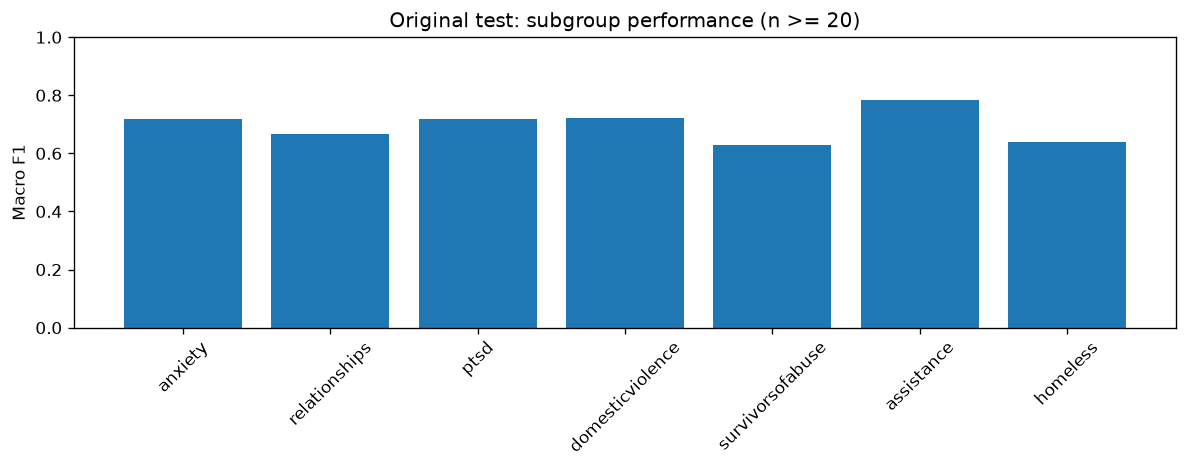

In [11]:
p,pred=saved_preds['tfidf_logistic_regression']
sub=test['subreddit'].astype(str).reset_index(drop=True)
sub_rows=[]
for community,n_rows in sub.value_counts().items():
    idx=(sub==community).to_numpy()
    if n_rows<20: continue
    r,_=evaluate(y_test.to_numpy()[idx],p[idx])
    sub_rows.append({'subreddit':community,'positive_rate':float(y_test.to_numpy()[idx].mean()),**r})
sub_df=pd.DataFrame(sub_rows).sort_values('n',ascending=False)
display(sub_df.round(3))
sub_df.to_csv(MET/'subreddit_subgroup_metrics.csv',index=False)
if len(sub_df):
    fig,ax=plt.subplots(figsize=(10,4))
    ax.bar(sub_df['subreddit'],sub_df['macro_f1'])
    ax.set_ylim(0,1);ax.set_ylabel('Macro F1');ax.set_title('Original test: subgroup performance (n >= 20)')
    ax.tick_params(axis='x',rotation=45)
    fig.tight_layout();fig.savefig(FIG/'04_subreddit_macro_f1.png',bbox_inches='tight');plt.show()


## 11. Save pipeline & verify round-trip for later SHAP/LIME

The artifact contains **TF-IDF and the trained Logistic Regression**. This makes `predict_proba(raw_texts)` available for explanation libraries. `joblib` serialization should only be loaded from trusted sources; never commit raw text or untrusted model files to a public repository.


In [12]:
model_file=MODEL/'dreaddit_tfidf_logreg.joblib'
joblib.dump(models['tfidf_logistic_regression'],model_file)
restored=joblib.load(model_file)
smoke=X_test.iloc[:5].tolist()
assert np.allclose(restored.predict_proba(smoke),models['tfidf_logistic_regression'].predict_proba(smoke))
print('Saved:',model_file.relative_to(ROOT),'| Bytes:',model_file.stat().st_size)
print('predict_proba sample shape:',restored.predict_proba(smoke).shape)


Saved: models\dreaddit_tfidf_logreg.joblib | Bytes: 935552
predict_proba sample shape: (5, 2)


## 12. Reproducibility manifest, risk limitations, and PP1 summary


In [13]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()

manifest={'project':'J26-IT-388 Component 4','notebook':'02_provisional_baseline',
 'generated_utc':datetime.now(timezone.utc).isoformat(),'seed':SEED,
 'training_data':{'path':'data/raw/dreaddit/dreaddit-train.csv','sha256':sha256(RAW/'dreaddit-train.csv'),'rows':len(train)},
 'test_data':{'path':'data/raw/dreaddit/dreaddit-test.csv','sha256':sha256(RAW/'dreaddit-test.csv'),'rows':len(test)},
 'features':['text'],'target':'label','classes':{'0':'non-stress-related text','1':'stress-related text'},
 'cv':'StratifiedGroupKFold 5 folds grouped by post_id; train only',
 'model':'word TF-IDF(1,2), min_df=2,max_df=0.95,max_features=20000 + LogisticRegression(C=1,solver=liblinear)',
 'decision_threshold':0.5,'model_artifact':'models/dreaddit_tfidf_logreg.joblib',
 'software':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
             'sklearn':sklearn.__version__,'scipy':scipy.__version__,'joblib':joblib.__version__,
             'matplotlib':matplotlib.__version__},
 'risks':['Text-only classifier is provisional and not a diagnosis.',
          'Three normalized text values appear in both splits; overlap-exclusion evaluation included.',
          'Repeated train post IDs; grouped train CV applied.',
          'Subreddit may be confounded with the target; subgroup audit included.',
          'No true longitudinal user histories; temporal scoring remains separate.',
          'A test set is not used for model selection, parameters, or decision threshold.']}
(MET/'reproducibility_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
readme="""# Notebook 02 — PP1 model evidence

- Task: binary **stress-related text** classification using Dreaddit (NOT clinical risk diagnosis).
- Model: fixed TF-IDF + Logistic Regression, compared with DummyClassifier.
- Data: original train/test split; training-only 5-fold `StratifiedGroupKFold` using `post_id`.
- Metrics: original held-out test once; contamination-excluded metrics and training dedup sensitivity reported separately.
- Outputs: CSV/JSON metrics, PNG figures and local-only saved pipeline.
- Restrictions: do not retune using original test labels; do not treat Reddit stress as mental-health diagnosis.
"""
(MET/'README.md').write_text(readme,encoding='utf-8')
print('NOTEBOOK 02 COMPLETE')
print('Model:',model_file)
print('Metrics files:',len(list(MET.iterdir())),'Figures:',len(list(FIG.glob('*.png'))))
print(results[['model','accuracy','macro_f1','roc_auc']].round(4).to_string(index=False))


NOTEBOOK 02 COMPLETE
Model: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\models\dreaddit_tfidf_logreg.joblib
Metrics files: 11 Figures: 4
                    model  accuracy  macro_f1  roc_auc
      dummy_most_frequent    0.5161    0.3404   0.5000
tfidf_logistic_regression    0.7161    0.7132   0.8162
